# 06 — De la demande au prix : l'optimisation

On dispose d'une courbe de demande. Il reste à répondre à la seule question qui
intéresse le métier : **quel prix poser ?**

Le problème s'écrit en une ligne :

$$ \max_p \; \pi(p) = (p - c) \cdot D(p) $$

Deux forces s'opposent — augmenter `p` augmente la marge unitaire mais réduit le
volume. L'optimum est le point où la perte de volume compense exactement le gain
de marge.

Trois approches sont construites et **comparées systématiquement**, parce
qu'aucune n'est fiable seule.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

# Le package est importable depuis le dossier notebooks/
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.25})

In [2]:
from optimization_pricing.config import DEFAULT_COST_RATIO, DEMAND_MODEL_PATH
from optimization_pricing.dataset import load_panel
from optimization_pricing.elasticity import load_elasticities
from optimization_pricing.modeling.demand_model import DemandModel

panel = load_panel("product", processed=True)
modele = DemandModel.load(DEMAND_MODEL_PATH)
elasticites = load_elasticities()

print(f"Modele : {modele.name}")
print(f"Elasticite de reference : {elasticites['reference_elasticity']:.3f}")

Modele : lightgbm_monotone
Elasticite de reference : -0.748


## L'hypothèse qui porte tout le reste : le coût

**Olist ne publie aucune donnée de coût.** Or sans coût marginal, `(p - c)` n'a
pas de valeur et il n'y a pas de profit à maximiser.

On pose donc `c = cost_ratio × prix observé`, avec `cost_ratio = 0.60` par
défaut (marge brute de 40 %, ordre de grandeur d'une marketplace de biens
physiques).

Ce n'est **pas** un détail technique : c'est l'hypothèse la plus structurante du
moteur. Elle est exposée dans l'API et dans le dashboard précisément pour être
challengée, et sa sensibilité est mesurée en fin de notebook.

## Approche 1 — La règle de Lerner (forme fermée)

Avec une demande à élasticité constante `D(p) = q₀ (p/p₀)^e`, l'optimum se
résout à la main :

$$ \frac{p^* - c}{p^*} = -\frac{1}{e} \qquad \Longleftrightarrow \qquad
   p^* = \frac{c}{1 + 1/e} $$

**Avantage** : transparent, auditable, explicable à un directeur commercial en
une phrase. **Limite** : ne vaut que si `e < -1`.

In [3]:
from optimization_pricing.optimizer import PricingConstraints, optimize_price_analytic

prix_actuel, volume_actuel = 200.0, 30.0

for e in (-3.0, -2.0, -1.5, -0.8):
    rec = optimize_price_analytic(prix_actuel, volume_actuel, e, cost_ratio=DEFAULT_COST_RATIO)
    contrainte = rec.binding_constraint or "aucune"
    print(
        f"e = {e:+.1f} -> prix {rec.recommended_price:7.2f} BRL "
        f"({rec.price_change:+6.1%})  profit {rec.profit_uplift:+6.1%}  | {contrainte}"
    )

e = -3.0 -> prix  180.00 BRL (-10.0%)  profit  +2.9%  | aucune
e = -2.0 -> prix  240.00 BRL (+20.0%)  profit  +4.2%  | aucune
e = -1.5 -> prix  250.00 BRL (+25.0%)  profit +16.3%  | borne de variation de prix
e = -0.8 -> prix  250.00 BRL (+25.0%)  profit +35.9%  | demande inelastique (e > -1) : optimum theorique non borne


Le dernier cas est révélateur. Quand la demande est **inélastique** (`e > -1`),
la dérivée du profit reste positive partout : le modèle de monopole pousse le
prix vers l'infini. La formule de Lerner ne renvoie alors rien d'exploitable.

C'est exactement la situation d'Olist (`e ≈ -0.74`), et c'est pourquoi les
garde-fous ne sont pas cosmétiques : ce sont eux qui rendent la recommandation
finie.

## Approche 2 — Recherche sur grille bornée

Même modèle de demande, mais l'optimum est cherché sur une grille de prix
délimitée par trois contraintes :

| Contrainte | Rôle |
|---|---|
| **bande de prix** (±25 %) | garde-fou commercial *et* statistique : au-delà, on extrapole hors des données |
| **marge plancher** (5 %) | ne jamais recommander de vendre à perte |
| **perte de volume max** (30 %) | un optimum qui détruit le volume dégrade le référencement, même s'il augmente le profit du mois |

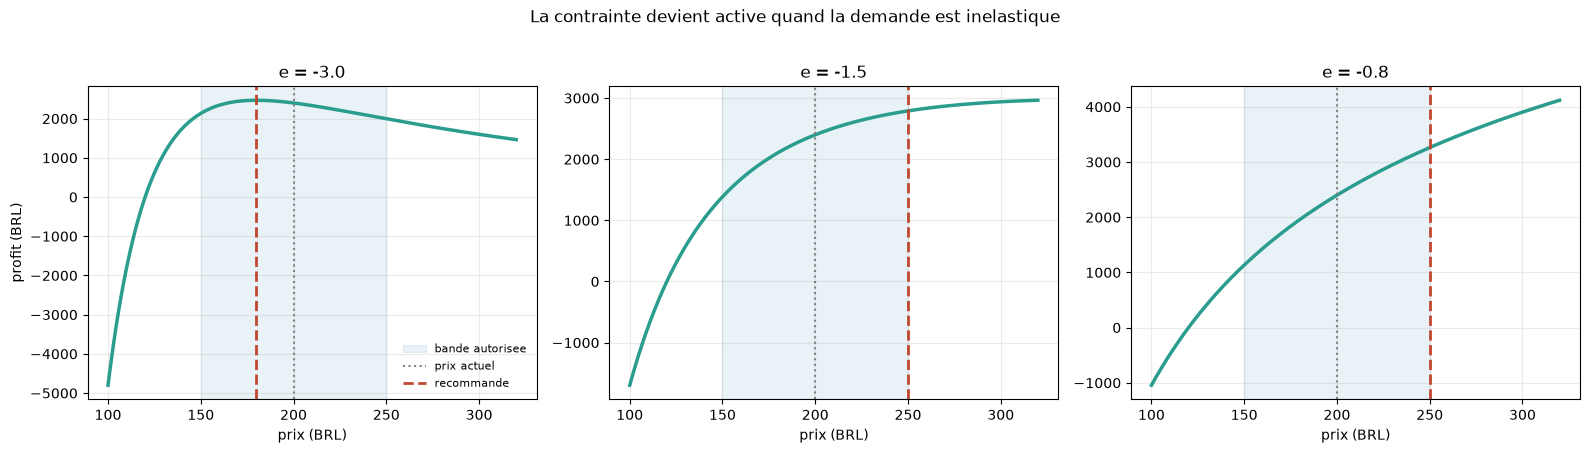

In [4]:
from optimization_pricing.optimizer import optimize_price_grid, profit_curve
from optimization_pricing.optimizer import constant_elasticity_demand

contraintes = PricingConstraints(max_change=0.25, min_margin_rate=0.05, max_volume_loss=0.30)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, e in zip(axes, (-3.0, -1.5, -0.8)):
    grille = np.linspace(prix_actuel * 0.5, prix_actuel * 1.6, 300)
    q = constant_elasticity_demand(grille, prix_actuel, volume_actuel, e)
    courbe = profit_curve(grille, q, DEFAULT_COST_RATIO * prix_actuel)

    rec = optimize_price_grid(prix_actuel, volume_actuel, e, cost_ratio=DEFAULT_COST_RATIO,
                              constraints=contraintes)
    bas, haut = contraintes.price_bounds(prix_actuel, DEFAULT_COST_RATIO * prix_actuel)

    ax.plot(courbe["price"], courbe["profit"], color="#2A9D8F", lw=2.5)
    ax.axvspan(bas, haut, color="#2E86AB", alpha=0.10, label="bande autorisee")
    ax.axvline(prix_actuel, color="grey", ls=":", label="prix actuel")
    ax.axvline(rec.recommended_price, color="#C1462F", ls="--", lw=2, label="recommande")
    ax.set_title(f"e = {e:+.1f}")
    ax.set_xlabel("prix (BRL)")
axes[0].set_ylabel("profit (BRL)")
axes[0].legend(frameon=False, fontsize=8)
plt.suptitle("La contrainte devient active quand la demande est inelastique", y=1.02)
plt.tight_layout()
plt.show()

À gauche (`e = -3`), l'optimum est **intérieur** : la courbe de profit a un
vrai maximum dans la bande. À droite (`e = -0.8`), le profit croît sur toute la
bande et la recommandation se colle au plafond — la contrainte fait la décision,
pas les données.

`binding_constraint` signale explicitement ce cas dans toutes les sorties du
moteur : une recommandation au bord n'a pas le même statut qu'un optimum interne.

## Approche 3 — Optimisation sur le modèle de demande ML

La demande vient maintenant du modèle entraîné. Un point technique est
**critique** ici.

> Quand on teste un prix contrefactuel, il ne suffit pas de changer la colonne
> `price`. Les features dérivées (`log_price`, `price_rel_product`,
> `price_rel_category`) doivent être **recalculées de façon cohérente**.

Sinon le modèle évalue un scénario impossible — un prix élevé avec un écart au
prix habituel inchangé — et la courbe de demande obtenue est plate par
construction. C'est le rôle de `apply_price_scenario`.

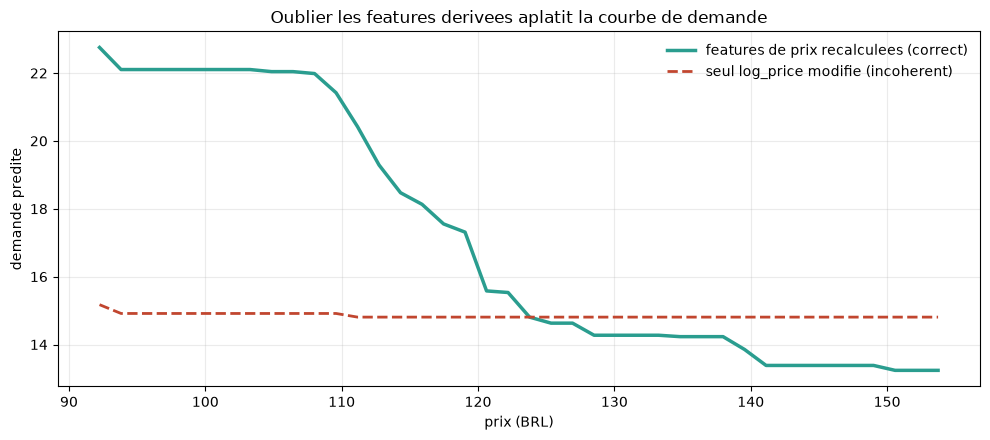

In [5]:
from optimization_pricing.features import apply_price_scenario

produit = panel.loc[panel["month"] == panel["month"].max()].nlargest(1, "quantity").reset_index(drop=True)
grille = np.linspace(produit["price"].iloc[0] * 0.75, produit["price"].iloc[0] * 1.25, 40)

# Version CORRECTE : toutes les features de prix recalculees
correct = apply_price_scenario(pd.concat([produit] * len(grille), ignore_index=True), grille)

# Version NAIVE : on ne change que log_price, on oublie les prix relatifs
naif = pd.concat([produit] * len(grille), ignore_index=True)
naif["price"] = grille
naif["log_price"] = np.log(grille)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(grille, modele.predict_demand(correct), color="#2A9D8F", lw=2.5,
        label="features de prix recalculees (correct)")
ax.plot(grille, modele.predict_demand(naif), color="#C1462F", lw=2, ls="--",
        label="seul log_price modifie (incoherent)")
ax.set_xlabel("prix (BRL)"); ax.set_ylabel("demande predite")
ax.set_title("Oublier les features derivees aplatit la courbe de demande")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

L'écart entre les deux courbes est la mesure directe de ce qu'on perdrait en
oubliant la cohérence des scénarios : la version naïve sous-estime largement la
réaction au prix, donc surestime le gain d'une hausse.

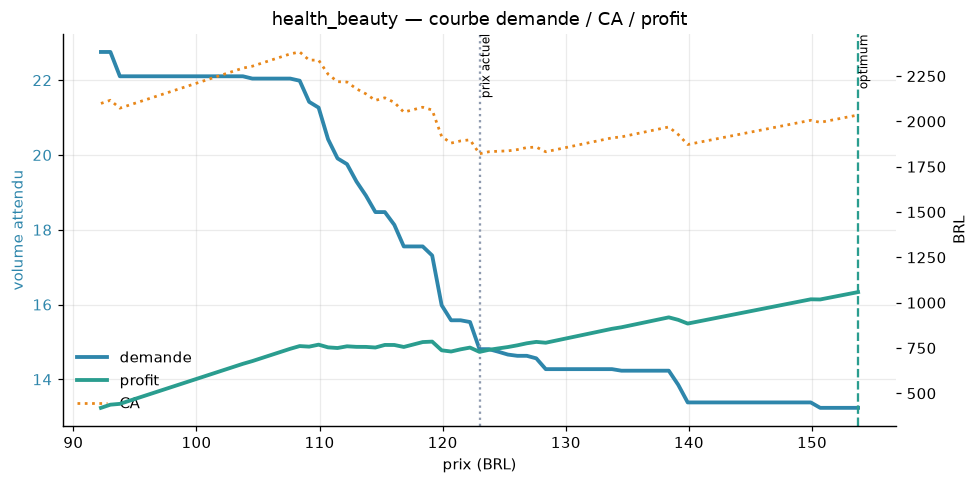

,valeur
ref_price,122.990
recommended_price,153.737
price_change,0.250
marginal_cost,73.794
elasticity,-1.799
ref_quantity,14.807
expected_quantity,13.238
volume_change,-0.106
ref_profit,728.456
expected_profit,"1,058.308"


In [6]:
from optimization_pricing.optimizer import optimize_with_model

rec_ml = optimize_with_model(modele, produit, cost_ratio=DEFAULT_COST_RATIO,
                             constraints=contraintes)

from optimization_pricing import plots

plots.plot_profit_curve(
    rec_ml.curve, rec_ml.ref_price, rec_ml.recommended_price,
    title=f"{produit['product_category_name_english'].iloc[0]} — courbe demande / CA / profit",
    save=True,
)
plt.show()

pd.Series(rec_ml.to_dict()).to_frame("valeur")

## Comparer les trois approches sur le même produit

Un écart important entre les méthodes est un **signal**, pas un bug : soit le
modèle ML capte un effet local que l'élasticité moyenne ignore, soit il
extrapole. Les trois sont affichées pour que l'arbitrage reste humain.

In [7]:
from optimization_pricing.elasticity import get_elasticity

categorie = produit["product_category_name_english"].iloc[0]
e_cat = get_elasticity(categorie, elasticites)
p0 = float(produit["price"].iloc[0])
q0 = float(modele.predict_demand(produit)[0])

rec_lerner = optimize_price_analytic(p0, q0, e_cat, cost_ratio=DEFAULT_COST_RATIO, constraints=contraintes)
rec_grille = optimize_price_grid(p0, q0, e_cat, cost_ratio=DEFAULT_COST_RATIO, constraints=contraintes)

comparaison = pd.DataFrame(
    [
        {"methode": "1. Lerner (forme fermee)", **rec_lerner.to_dict()},
        {"methode": "2. Grille, elasticite constante", **rec_grille.to_dict()},
        {"methode": "3. Modele de demande ML", **rec_ml.to_dict()},
    ]
)[["methode", "recommended_price", "price_change", "elasticity", "volume_change",
   "profit_uplift", "binding_constraint"]]
comparaison

,methode,recommended_price,price_change,elasticity,volume_change,profit_uplift,binding_constraint
0,1. Lerner (forme fermee),153.737,0.250,-0.869,-0.176,0.339,demande inelastique (e > -1) : optimum theoriq...
1,"2. Grille, elasticite constante",153.737,0.250,-0.869,-0.176,0.339,borne haute de variation de prix
2,3. Modele de demande ML,153.737,0.250,-1.799,-0.106,0.453,borne haute de variation de prix


## L'analyse de sensibilité au coût

C'est le tableau à mettre en face d'un directeur financier : *voici ce que le
moteur recommande selon VOTRE taux de marge réel.*

In [8]:
from optimization_pricing.optimizer import breakeven_elasticity, cost_ratio_sensitivity

sensibilite = cost_ratio_sensitivity(p0, q0, e_cat, constraints=contraintes)
sensibilite[["cost_ratio", "implied_margin_rate", "breakeven_elasticity",
             "recommended_price", "price_change", "profit_uplift"]]

,cost_ratio,implied_margin_rate,breakeven_elasticity,recommended_price,price_change,profit_uplift
0,0.400,0.600,-1.667,153.737,0.250,0.167
1,0.450,0.550,-1.818,153.737,0.250,0.198
2,0.500,0.500,-2.000,153.737,0.250,0.236
3,0.550,0.450,-2.222,153.737,0.250,0.281
4,0.600,0.400,-2.500,153.737,0.250,0.339
5,0.650,0.350,-2.857,153.737,0.250,0.412
6,0.700,0.300,-3.333,153.737,0.250,0.510
7,0.750,0.250,-4.000,153.737,0.250,0.648
8,0.800,0.200,-5.000,153.737,0.250,0.854
9,0.850,0.150,-6.667,153.737,0.250,1.197


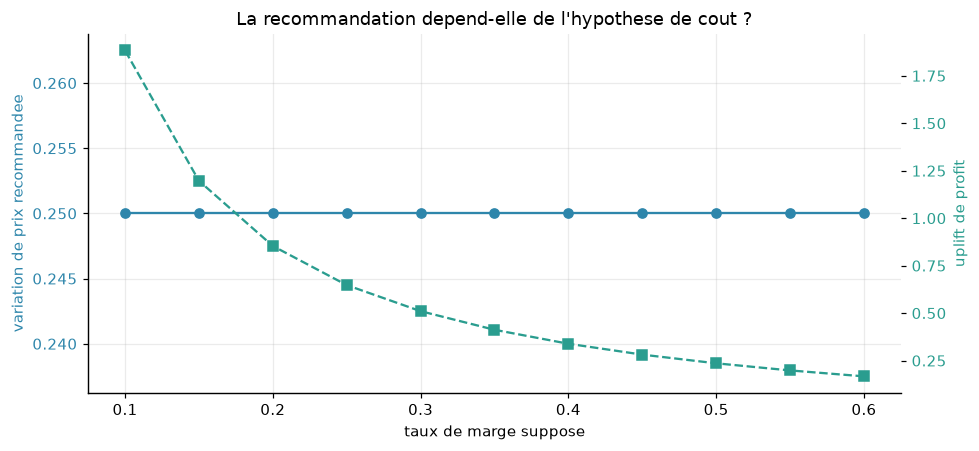

Elasticite de la categorie 'health_beauty' : -0.87

  marge 20% -> seuil  -5.00 -> sous-tarife
  marge 30% -> seuil  -3.33 -> sous-tarife
  marge 40% -> seuil  -2.50 -> sous-tarife
  marge 50% -> seuil  -2.00 -> sous-tarife


In [9]:
plots.plot_cost_sensitivity(sensibilite, save=True)
plt.show()

print(f"Elasticite de la categorie '{categorie}' : {e_cat:.2f}")
print()
for marge in (0.20, 0.30, 0.40, 0.50):
    seuil = breakeven_elasticity(marge)
    verdict = "sous-tarife" if e_cat > seuil else "sur-tarife"
    print(f"  marge {marge:.0%} -> seuil {seuil:6.2f} -> {verdict}")

**La direction de la recommandation ne change pas** sur toute la plage de marges
plausibles : quelle que soit l'hypothèse retenue entre 20 % et 50 %, l'élasticité
mesurée reste au-dessus du seuil de rentabilité. C'est la conclusion robuste.

Ce qui change, c'est l'**ampleur** de l'uplift annoncé — et c'est précisément ce
chiffre qu'il ne faut pas promettre au métier sans connaître les coûts réels.

## Le garde-fou qui manque : l'amortissement

Une dernière protection, moins évidente et pourtant essentielle. **La courbe de
profit est plate autour de son optimum.** Conséquence : n'appliquer que la
moitié du mouvement recommandé coûte très peu d'uplift, alors que se tromper de
direction coûte cher.

In [10]:
courbe = rec_ml.curve
profit_max = courbe["profit"].max()
profit_actuel_ = np.interp(p0, courbe["price"], courbe["profit"])
prix_moitie = p0 + 0.5 * (rec_ml.recommended_price - p0)
profit_moitie = np.interp(prix_moitie, courbe["price"], courbe["profit"])

gain_total = profit_max - profit_actuel_
gain_moitie = profit_moitie - profit_actuel_

print(f"Mouvement complet   : {rec_ml.price_change:+.1%} -> gain {gain_total:,.2f} BRL (100 %)")
print(f"Mouvement amorti 50%: {prix_moitie / p0 - 1:+.1%} -> gain {gain_moitie:,.2f} BRL "
      f"({gain_moitie / max(gain_total, 1e-9):.0%} du gain)")
print()
print("On conserve l'essentiel du gain en divisant par deux l'exposition au risque.")

Mouvement complet   : +25.0% -> gain 329.85 BRL (100 %)
Mouvement amorti 50%: +12.5% -> gain 190.47 BRL (58% du gain)

On conserve l'essentiel du gain en divisant par deux l'exposition au risque.


## Optimisation du portefeuille complet

In [11]:
from optimization_pricing.optimizer import optimize_portfolio, portfolio_summary

dernier_mois = panel["month"].max()
catalogue = panel.loc[panel["month"] == dernier_mois].copy()

politique = optimize_portfolio(modele, catalogue, cost_ratio=DEFAULT_COST_RATIO,
                               constraints=contraintes)
resume = portfolio_summary(politique)
pd.Series(resume).to_frame("valeur")

2026-08-20 10:44:04.384 | INFO     | optimization_pricing.optimizer:optimize_portfolio:517 - Politique tarifaire sur 1,423 lignes | variation de prix mediane +25.0% | profit agrege +35.3%


,valeur
n_items,"1,423.000"
share_price_up,0.972
share_price_down,0.026
share_unchanged,0.002
median_price_change,0.250
share_at_ceiling,0.846
share_at_floor,0.000
ref_profit,"126,758.166"
expected_profit,"171,514.107"
profit_uplift,0.353


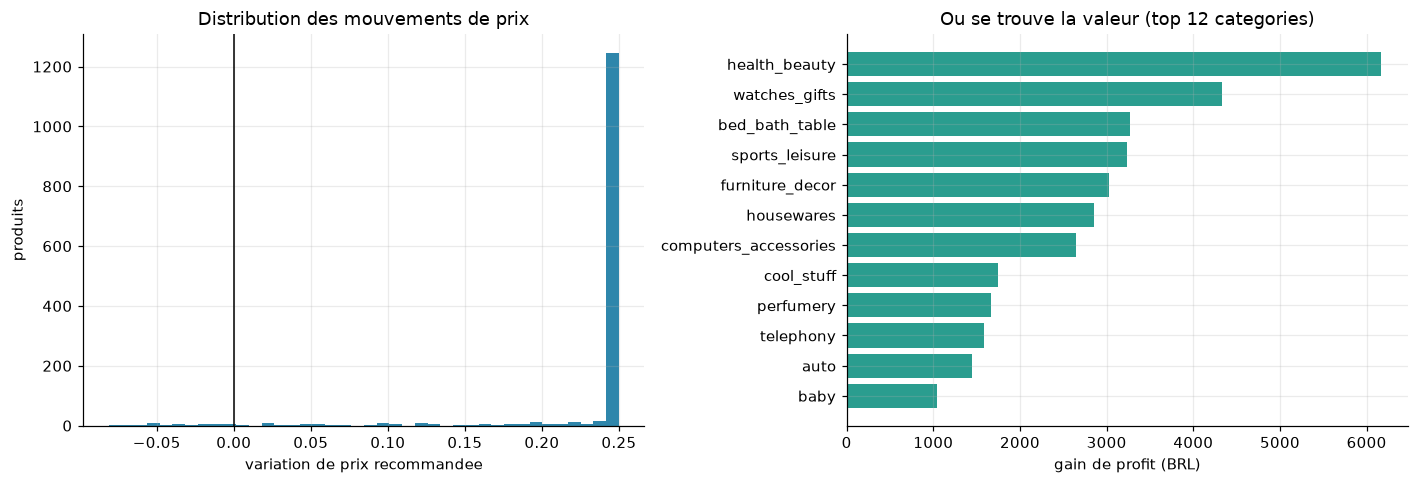

In [12]:
plots.plot_policy_distribution(politique, save=True)
plt.show()

### Le résultat inconfortable, et pourquoi il faut le dire

Une large majorité des produits est recommandée **au plafond** de +25 %. Leur
optimum théorique est au-delà de la bande autorisée : la recommandation est
gouvernée par le garde-fou, pas par les données.

Le message opérationnel n'est donc **pas** « appliquer +25 % partout ». C'est :

1. les données disent que les prix Olist sont en dessous du niveau optimal ;
2. mais l'ampleur de la hausse sort du domaine où le modèle a appris ;
3. donc : **augmenter par paliers et mesurer**, pas appliquer d'un coup.

Un moteur de prix qui livrerait « +25 % » sans ce diagnostic serait dangereux.

In [13]:
# Effet de l'amortissement sur le portefeuille entier
from optimization_pricing.optimizer import apply_damping

lignes = []
for d in (1.0, 0.75, 0.5, 0.25):
    amortie = apply_damping(politique, d)
    s = portfolio_summary(amortie)
    lignes.append({
        "amortissement": d,
        "variation de prix mediane": s["median_price_change"],
        "uplift de profit": s["profit_uplift"],
        "variation de volume": s["volume_change"],
    })
pd.DataFrame(lignes)

,amortissement,variation de prix mediane,uplift de profit,variation de volume
0,1.000,0.250,0.353,-0.104
1,0.750,0.188,0.271,-0.083
2,0.500,0.125,0.186,-0.058
3,0.250,0.062,0.096,-0.031


## Où se trouve réellement la valeur

In [14]:
from optimization_pricing.config import CATEGORY_COL

par_categorie = (
    politique.groupby(CATEGORY_COL)
    .agg(
        produits=("ref_price", "size"),
        variation_mediane=("price_change", "median"),
        profit_actuel=("ref_profit", "sum"),
        profit_attendu=("expected_profit", "sum"),
    )
    .assign(
        gain=lambda d: d["profit_attendu"] - d["profit_actuel"],
        uplift=lambda d: d["profit_attendu"] / d["profit_actuel"] - 1,
    )
    .sort_values("gain", ascending=False)
)
par_categorie.head(12)

,produits,variation_mediane,profit_actuel,profit_attendu,gain,uplift
product_category_name_english,,,,,,
health_beauty,154,0.250,"19,550.985","25,719.911","6,168.925",0.316
watches_gifts,97,0.250,"13,735.387","18,066.467","4,331.080",0.315
bed_bath_table,161,0.250,"10,176.448","13,443.198","3,266.749",0.321
sports_leisure,112,0.250,"8,462.121","11,697.362","3,235.241",0.382
furniture_decor,94,0.250,"8,878.978","11,903.405","3,024.427",0.341
housewares,104,0.250,"6,497.043","9,356.206","2,859.162",0.440
computers_accessories,85,0.250,"8,919.639","11,561.260","2,641.621",0.296
cool_stuff,36,0.250,"4,831.314","6,577.110","1,745.795",0.361
perfumery,38,0.250,"4,447.030","6,107.176","1,660.147",0.373


## Ce que ce notebook établit

* Trois optimiseurs cohabitent : **Lerner** (transparent), **grille** (gère les
  contraintes), **ML** (capte les non-linéarités). Les trois sont comparés
  systématiquement plutôt qu'arbitrés d'avance.
* La règle de Lerner **ne s'applique pas** ici (`e > -1`) : ce sont les
  garde-fous qui rendent la recommandation finie.
* `apply_price_scenario` est le point technique critique : oublier de recalculer
  les features dérivées aplatit artificiellement la courbe de demande.
* La direction de la recommandation est **robuste** à l'hypothèse de coût ;
  son ampleur ne l'est pas.
* 85 % des produits butent sur le plafond → la recommandation est un **plan de
  test**, pas une grille à appliquer telle quelle.

**Suite :** notebook 07, la quantification de l'impact et le plan de déploiement.